# Studio delle variazioni spettrali di Zeta Gem

Zeta gem è una cefeide classica con un periodo di circa 10.15 giorni. Le cefeidi classiche, oltre la periodica variazione di luminosità, presentano anche una variazione di classe spettrale.<br>
Si vuole studiare come variano la larghezza equivalente e la FWHM delle principali righe spettrali all'intreno del ciclo di luminosità.
La fase di ogni singola osservazione è stata calcolata tramite le effemeridi fornite da [AAVSO](https://vsx.aavso.org/index.php?view=detail.top&oid=14665).<br>
Sono state effettuate osservazioni nel corso di diverse notti e per ognuna è stato prodotto un file CSV contenente le misure di larghezza equivalente e FWHM delle principali righe.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Per ogni sessione di osservazione viene riportato:
- jdate -> julian date dell'osservazione
- prev_min -> julian date del minimo di luminosità subito precedente. Ricavato dalle effemeridi [AAVSO](https://vsx.aavso.org/index.php?view=detail.top&oid=14665)
- date -> data gregoriana dell'osservazione ("yyyymmdd") da cui ricavare il nome del file CSV con le misurazioni

In [2]:
measures = [{
    "jdate": 2461097.264,
    "prev_min": 2461091.032,
    "date": "20250225"
},
{
    "jdate": 2461098.261,
    "prev_min": 2461091.032,
    "date": "20250226"
},
{
    "jdate": 2461100.269,
    "prev_min": 2461091.032,
    "date": "20250228"
},
{
    "jdate": 2461154.317,
    "prev_min": 2461151.931,
    "date": "20250423"
},
{
    "jdate": 2461155.32,
    "prev_min": 2461151.931,
    "date": "20250424"
},
{
    "jdate": 2461157.308,
    "prev_min": 2461151.931,
    "date": "20250426"
}
]

### Calcolo della fase e caricamento dati di EW e FWHM

In [3]:
LUM_PERIOD = 10.15 # Periodo del ciclo di luminosità (fonte AAVSO)

measures_df = pd.DataFrame(measures)
measures_df["phase"] = (measures_df["jdate"] - measures_df["prev_min"]) / LUM_PERIOD
measures_df

,jdate,prev_min,date,phase
0,2461097.264,2461091.032,20250225,0.613990
1,2461098.261,2461091.032,20250226,0.712217
2,2461100.269,2461091.032,20250228,0.910049
3,2461154.317,2461151.931,20250423,0.235074
4,2461155.320,2461151.931,20250424,0.333892
5,2461157.308,2461151.931,20250426,0.529754


In [4]:
all_ews = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm"))
for i, measure in measures_df.iterrows():
    file_name = "ew_zeta_gem_"+measure["date"]+".csv"
    ews = pd.read_csv(file_name)
    ews["phase"] = measure["phase"]
    all_ews = pd.concat([all_ews, ews], axis=0)


### Studio di H alfa

<Figure size 1500x600 with 0 Axes>

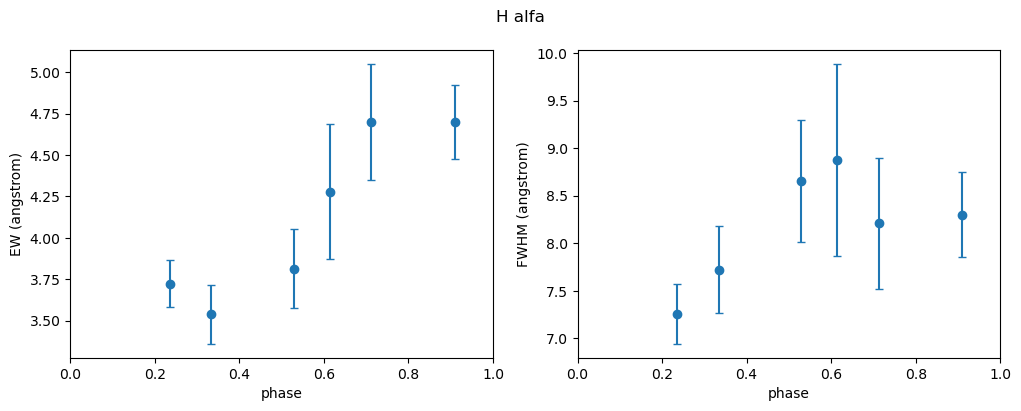

In [5]:
Halfa = all_ews[all_ews["line_name"] == "H alfa"]
Halfa = Halfa.sort_values(by=["phase"], ascending=True)
plt.figure(figsize=(15, 6))
fig, axs = plt.subplots(nrows=1, ncols=2, sharex=True)
fig.set_figwidth(12)
fig.set_figheight(4)
fig.suptitle("H alfa")
ax = axs[0]
ax.set_xlabel("phase")
ax.set_ylabel("EW (angstrom)")
ax.set_xlim(left=0.0, right=1.0)
ax.errorbar(Halfa["phase"], Halfa["ew"], yerr=Halfa["delta_ew"], fmt="o", capsize=3)
ax = axs[1]
ax.set_xlabel("phase")
ax.set_ylabel("FWHM (angstrom)")
ax.errorbar(Halfa["phase"], Halfa["fwhm"], yerr=Halfa["delta_fwhm"], fmt="o", capsize=3)
plt.show()

### Studio di H beta

<Figure size 1500x600 with 0 Axes>

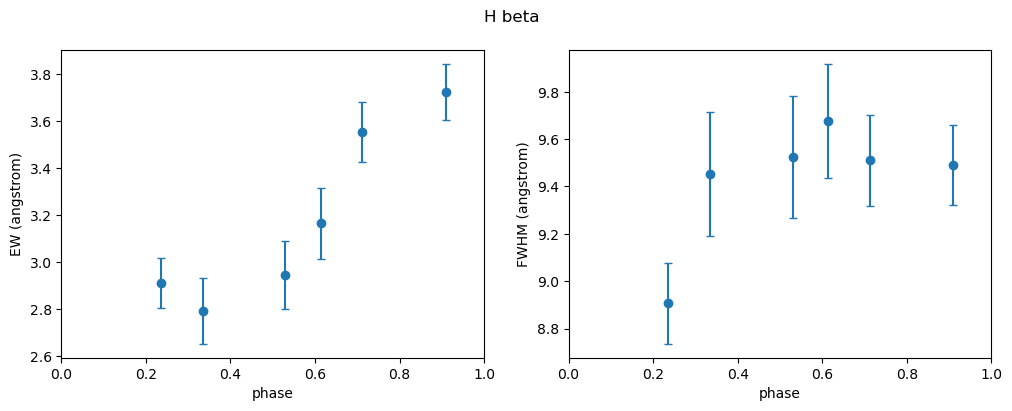

In [6]:
Hbeta = all_ews[all_ews["line_name"] == "H beta blend [4861.0]"]
Hbeta = Hbeta.sort_values(by=["phase"], ascending=True)
plt.figure(figsize=(15, 6))
fig, axs = plt.subplots(nrows=1, ncols=2, sharex=True)
fig.set_figwidth(12)
fig.set_figheight(4)
fig.suptitle("H beta")
ax = axs[0]
ax.set_xlabel("phase")
ax.set_ylabel("EW (angstrom)")
ax.set_xlim(left=0.0, right=1.0)
ax.errorbar(Hbeta["phase"], Hbeta["ew"], yerr=Hbeta["delta_ew"], fmt="o", capsize=3)
ax = axs[1]
ax.set_xlabel("phase")
ax.set_ylabel("FWHM (angstrom)")
ax.errorbar(Hbeta["phase"], Hbeta["fwhm"], yerr=Hbeta["delta_fwhm"], fmt="o", capsize=3)
plt.show()

### Studio di Hgamma

<Figure size 1500x600 with 0 Axes>

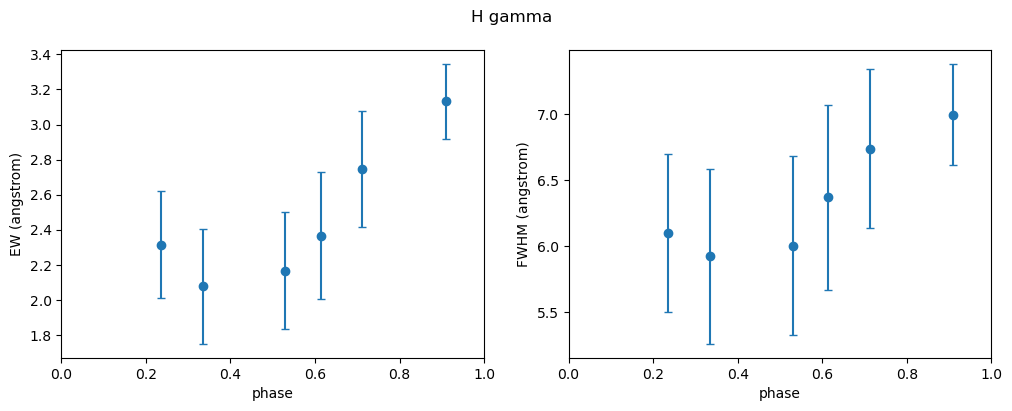

In [7]:
Hgamma = all_ews[all_ews["line_name"] == "H gamma blend [4341.0]"]
Hgamma = Hgamma.sort_values(by=["phase"], ascending=True)
plt.figure(figsize=(15, 6))
fig, axs = plt.subplots(nrows=1, ncols=2, sharex=True)
fig.set_figwidth(12)
fig.set_figheight(4)
fig.suptitle("H gamma")
ax = axs[0]
ax.set_xlabel("phase")
ax.set_ylabel("EW (angstrom)")
ax.set_xlim(left=0.0, right=1.0)
ax.errorbar(Hgamma["phase"], Hgamma["ew"], yerr=Hgamma["delta_ew"], fmt="o", capsize=3)
ax = axs[1]
ax.set_xlabel("phase")
ax.set_ylabel("FWHM (angstrom)")
ax.errorbar(Hgamma["phase"], Hgamma["fwhm"], yerr=Hgamma["delta_fwhm"], fmt="o", capsize=3)
plt.show()

### Studio di H delta

<Figure size 1500x600 with 0 Axes>

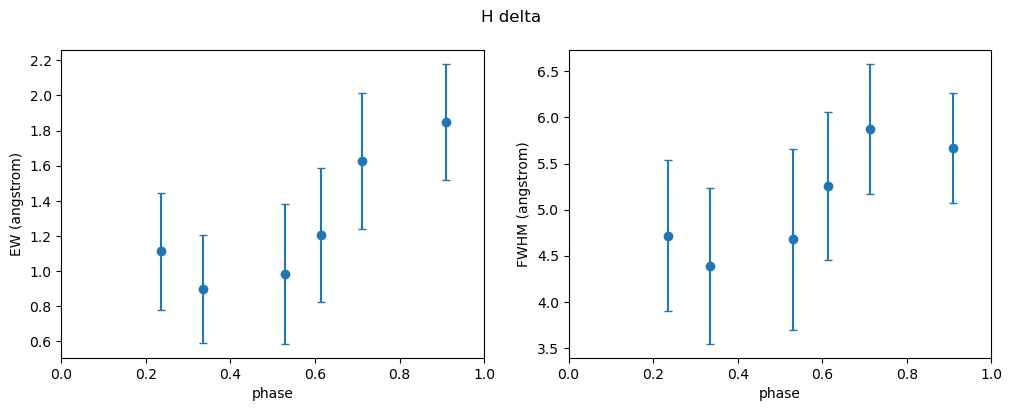

In [8]:
Hdelta = all_ews[all_ews["line_name"] == "H delta blend [4101.0]"]
Hdelta = Hdelta.sort_values(by=["phase"], ascending=True)
plt.figure(figsize=(15, 6))
fig, axs = plt.subplots(nrows=1, ncols=2, sharex=True)
fig.set_figwidth(12)
fig.set_figheight(4)
fig.suptitle("H delta")
ax = axs[0]
ax.set_xlabel("phase")
ax.set_ylabel("EW (angstrom)")
ax.set_xlim(left=0.0, right=1.0)
ax.errorbar(Hdelta["phase"], Hdelta["ew"], yerr=Hdelta["delta_ew"], fmt="o", capsize=3)
ax = axs[1]
ax.set_xlabel("phase")
ax.set_ylabel("FWHM (angstrom)")
ax.errorbar(Hdelta["phase"], Hdelta["fwhm"], yerr=Hdelta["delta_fwhm"], fmt="o", capsize=3)
plt.show()

### Studio di Ca I 4226

<Figure size 1500x600 with 0 Axes>

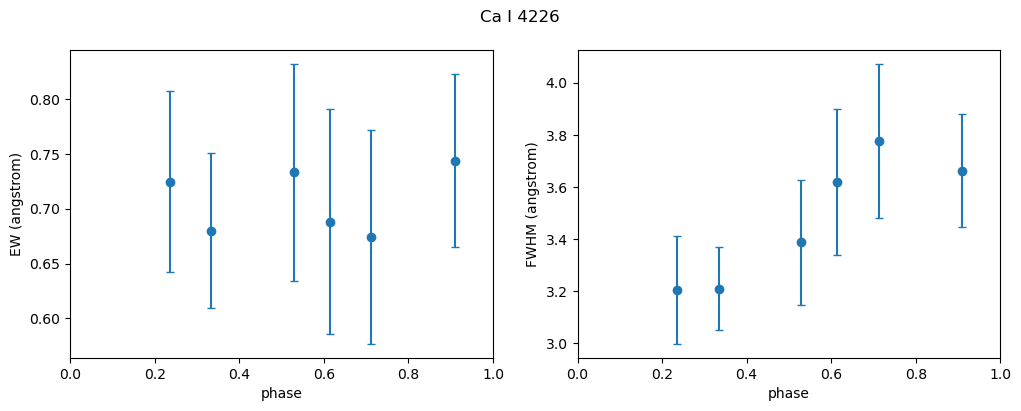

In [9]:
CaI4226 = all_ews[all_ews["line_name"] == "Ca I 4226"]
CaI4226 = CaI4226.sort_values(by=["phase"], ascending=True)
plt.figure(figsize=(15, 6))
fig, axs = plt.subplots(nrows=1, ncols=2, sharex=True)
fig.set_figwidth(12)
fig.set_figheight(4)
fig.suptitle("Ca I 4226")
ax = axs[0]
ax.set_xlabel("phase")
ax.set_ylabel("EW (angstrom)")
ax.set_xlim(left=0.0, right=1.0)
ax.errorbar(CaI4226["phase"], CaI4226["ew"], yerr=CaI4226["delta_ew"], fmt="o", capsize=3)
ax = axs[1]
ax.set_xlabel("phase")
ax.set_ylabel("FWHM (angstrom)")
ax.errorbar(CaI4226["phase"], CaI4226["fwhm"], yerr=CaI4226["delta_fwhm"], fmt="o", capsize=3)
plt.show()